### Langchain

In [78]:
import langchain
langchain.__version__

'1.4.9'

In [79]:
import os
import json
from langchain.agents import create_agent
from langchain_core.tools import tool
from langchain_groq import ChatGroq
from langchain_community.tools.tavily_search import TavilySearchResults
from dotenv import load_dotenv

### Load API Keys

In [80]:
load_dotenv()

os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")
os.environ["TAVILY_API_KEY"] = os.getenv("TAVILY_API_KEY")

In [81]:
search_tool = TavilySearchResults(max_results=3)

### Custom Tool for Analysis

In [82]:
@tool
def search_company_tech_stack(company_name: str) -> str:
    """Search the web for the target company's recent tech stack, AI initiatives, or engineering blog."""
    try:
        results = search_tool.invoke(f"{company_name} AI engineering tech stack blog")
        return json.dumps(results, indent=2, default=str)
    except Exception as e:
        return f"SEARCH_FAILED: {type(e).__name__}: {e}"

### Initialize the Model

In [83]:
model = ChatGroq(model="openai/gpt-oss-120b", temperature=0.2)


### Create the Agent

In [84]:
tools = [search_company_tech_stack]

system_prompt = """You are an elite AI Career Coach. 
Your goal is to help the user land a job in an AI team. 
When the user provides a Job Description (JD) and their Resume, you MUST:
1. Use 'search_company_tech_stack' to research the company's recent AI projects.
2. Identify the top 3 technical skills the company prioritizes.
3. Compare the user's resume to the JD and list 2 specific skill gaps.
4. Generate 3 technical mock interview questions tailored to those gaps.
Format your response clearly with Markdown headers."""

agent = create_agent(
    model=model,
    tools=tools,
    system_prompt=system_prompt
)

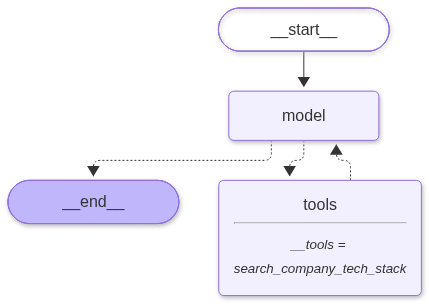

In [85]:
agent

### Sample Data 

In [86]:
# 5. Define Sample Data
job_description = """
Company: Anthropic
Role: AI Engineer (Agentic AI Team)
Requirements: Strong Python, experience with LangChain or LangGraph, 
familiarity with RAG pipelines, and experience deploying LLMs via FastAPI.
"""

resume_text = """
Jane Doe - Python Developer
Experience: 3 years building Django web apps. 
Familiar with OpenAI API and basic prompt engineering. 
Built a simple chatbot using Streamlit.
"""

user_query = f"""
Here is the Job Description:
{job_description}

Here is my Resume:
{resume_text}

Please act as my career coach and prepare me for this interview.
"""

### Invoke the Agent

In [87]:
print("🤖 Agent is analyzing your profile and researching the company...\n")
response = agent.invoke({
    "messages": [{"role": "user", "content": user_query}]
})

🤖 Agent is analyzing your profile and researching the company...



In [88]:
agent.invoke({
    "messages": [{"role": "user", "content": user_query}]
})

{'messages': [HumanMessage(content='\nHere is the Job Description:\n\nCompany: Anthropic\nRole: AI Engineer (Agentic AI Team)\nRequirements: Strong Python, experience with LangChain or LangGraph, \nfamiliarity with RAG pipelines, and experience deploying LLMs via FastAPI.\n\n\nHere is my Resume:\n\nJane Doe - Python Developer\nExperience: 3 years building Django web apps. \nFamiliar with OpenAI API and basic prompt engineering. \nBuilt a simple chatbot using Streamlit.\n\n\nPlease act as my career coach and prepare me for this interview.\n', additional_kwargs={}, response_metadata={}, id='4b1ea3e1-8df1-4910-a641-920f98bfcb55'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'We need to follow instructions: Use search_company_tech_stack to research Anthropic\'s recent AI projects. Then identify top 3 technical skills the company prioritizes. Compare resume to JD, list 2 skill gaps. Generate 3 technical mock interview questions tailored to those gaps. Format with markdow

### Print the Final Output

In [89]:
print(response["messages"][-1].content)

## 📋 Top 3 Technical Skills Anthropic’s Agentic AI Team Prioritizes  
*(Based on publicly‑available information about Anthropic’s recent AI projects such as Claude 3, tool‑use agents, and Retrieval‑Augmented Generation pipelines)*  

| # | Skill | Why Anthropic cares about it |
|---|-------|------------------------------|
| **1** | **Advanced Python for LLM orchestration** (including async, type‑hints, testing) | All of Anthropic’s production agents are written in Python; the codebase heavily uses modern Python features to glue together LLM calls, tool use, and safety checks. |
| **2** | **LangChain / LangGraph (or equivalent agentic frameworks)** | Their “Agentic AI” roadmap explicitly mentions building composable agents with LangChain‑style abstractions and graph‑based control flow (LangGraph). |
| **3** | **RAG pipelines & FastAPI‑based LLM serving** | Recent blog posts show Anthropic exposing Claude via FastAPI endpoints and integrating external knowledge sources through Retrieval‑